In [9]:
transport_coeffs

['Da_t', 'Xe_t', 'Xi_t', 'ddr_Tetot_txy', 'ddr_Titot_txy', 'ddr_nitot_txy']

In [1]:
import sys
sys.path.append("/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts")
import os
import sys
import yaml
import numpy as np
from pathlib import Path
import re
import numpy as np
import netCDF4 as nc
import yaml
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, fixed
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_bout_midplane_distances
from converged_profile_functions import unbiased_convergence, end_biased_convergence

DEFAULT_CONFIG_PATH = "SIBIL_config.yaml"

config_path = DEFAULT_CONFIG_PATH

if not os.path.exists(config_path):
    print(f"Error: config file not found: {config_path}")
    sys.exit(1)

config = load_config(config_path)
sibil_config_summary(config)

# if not confirm():
#     print("Aborted. No changes made.")
#     sys.exit(0)

import sibil  # imported here so summary/confirmation works without dependency installed

INPUT_FILE  = f"{config["base_path"]}/{config["iteration"]}_iteration/b2.transport.inputfile"
OUTPUT_FILE = f"{config["base_path"]}/{int(config["iteration"])+1}_iteration/b2.transport.inputfile"
bout_dir  = Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bout_dir"]}")
data_dir  = bout_dir / "numpy"
grid_fname= Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bgrid"]}")
grid_fname = str(grid_fname)
transport_coeffs = config["bout_to_solps_pass"]["passed_coeffs"]
profile_sample_timestep = config["bout_to_solps_pass"]["profile_sample_timestep"]
jomp = config["bout_to_solps_pass"]["jomp"]
N, l = config["bout_to_solps_pass"]["N"], config["bout_to_solps_pass"]["l"]

grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

psin = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

sepx_dists_solps = extract_tdata_first_index(INPUT_FILE)
psin_mid, sepx_dists_bout = get_bout_midplane_distances(grid_fname)

convergent_transport_coeffs = {}
interplted_transport_coeffs = {}
# "ddr_Tetot_txy", "ddr_Titot_txy", 
#                                        "ddr_nitot_txy", 
transport_coeffs = transport_coeffs + [#"Vr_t",
                                       "ddr_Tetot_txy", "ddr_Titot_txy", 
                                       "ddr_nitot_txy", 
                                       #"Vexbx_txy", "Vbtildx_txy"
]
for var_name in transport_coeffs:
    var = np.load(f"{data_dir}/{var_name}.npy")
    var_conv = unbiased_convergence(var, N, l)
    var_conv_midplane = var_conv[profile_sample_timestep,:,jomp]
    var_conv_interpolated = interpolate_dataset(sepx_dists_bout,var_conv_midplane,sepx_dists_solps)
    nan_mask = np.isnan(var_conv_interpolated)
    var_conv_interpolated[nan_mask]=0
    
    convergent_transport_coeffs[var_name] = var_conv
    interplted_transport_coeffs[var_name] = var_conv_interpolated

SIBIL Midplane Mapper — Configuration Summary
  G-file         : ../g184016.03200  [OK]
  Geometry file  : ../baserun/HvsD_Dmesh_noC_v1.v001.geo  [OK]
  B-grid file    : Shelf_new_grid2_sinks2_gradfix/d3d_shelf_184016.03200_nc3.grd.nc  [OK]
  b2fstate       : b2fstate  [OK]
  b2fplasmf      : b2fplasmf  [OK]
  b2fgmtry       : b2fgmtry  [OK]

  Softmax scales (max, min):
    ni  : max=1e+16, min=1e+15
    ne  : max=1e+16, min=1e+15
    Ti  : max=0.5, min=0.0001
    Te  : max=0.5, min=0.0001
SIBIL Succsessfully Imported


array                 shape                    nt
--------------------------------------------------
Da_t                  (15, 260, 64)            15
Xe_t                  (15, 260, 64)            15
Xi_t                  (15, 260, 64)            15
ddr_Tetot_txy         (15, 260, 64)            15
ddr_Titot_txy         (15, 260, 64)            15
ddr_nitot_txy         (15, 260, 64)            15
--------------------------------------------------
OK: all time-dependent arrays have nt = 15


0/6  array shape / provenance consistency
array                 shape                    nt
--------------------------------------------------
Da_t                  (15, 260, 64)            15
Xe_t                  (15, 260, 64)            15
Xi_t                  (15, 260, 64)            15
ddr_Tetot_txy         (15, 260, 64)            15
ddr_Titot_txy         (15, 260, 64)            15
ddr_nitot_txy         (15, 260, 64)            15
--------------------------------------------------
OK: all time-dependent arrays have nt = 15

using j = 48, t = 14  (nt = 15, ny = 64)

1/6  chi 0/0 artifact
[Da_t] 260 masked cell(s); peak drops by xnan when the vanishing-gradient cells are removed.
[Xe_t] 260 masked cell(s); peak drops by xnan when the vanishing-gradient cells are removed.
[Xi_t] 260 masked cell(s); peak drops by xnan when the vanishing-gradient cells are removed.


/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts/sibil_debug_diagnostics.py:369: RuntimeWarning: All-NaN slice encountered
  ratio = np.nanmax(np.abs(y_raw)) / (np.nanmax(np.abs(y_msk)) + 1e-300)


  saved ./crash_diagnostics/chi_artifact_j48_t14.png


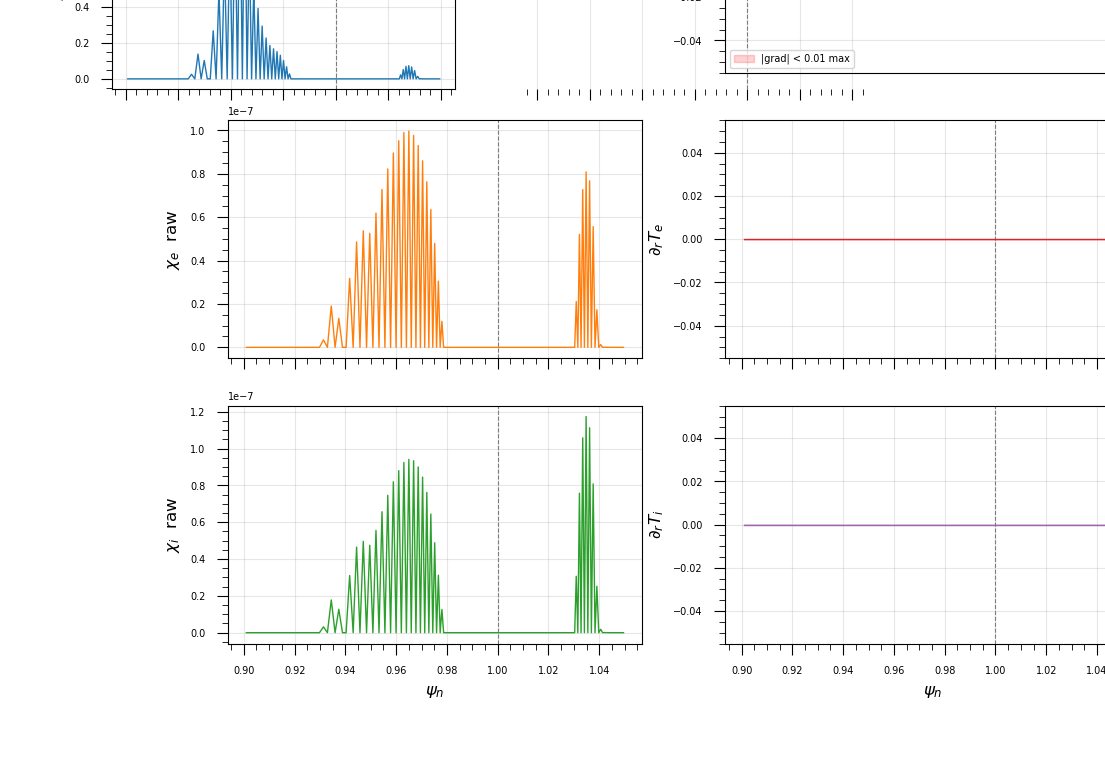

2/6  equilibrium / grid-file discontinuity check  <-- most likely bug
grid variables used: {'Te0': 'Teexp', 'Ti0': 'Tiexp', 'Ni0': 'Niexp', 'P0': 'pressure', 'Jpar0': 'Jpar0'}
  |$Te0''$| within |psi_n-1|<0.03 reaches 1.00 of its global max  <-- SPIKE AT SEPARATRIX
  |$Ti0''$| within |psi_n-1|<0.03 reaches 1.00 of its global max  <-- SPIKE AT SEPARATRIX
  |$ni0''$| within |psi_n-1|<0.03 reaches 1.00 of its global max  <-- SPIKE AT SEPARATRIX
  dx non-uniformity exceeds 5% in 0 cells (max 0.03 at psi_n=0.9938)
  Bpxy hits the 0.04 floor in 0 cells at this poloidal index.
  force-balance residual near separatrix: 0.85 (relative). Large values mean smoothing jpar0 broke grad(P0) = J0 x B0 and the code will drive a relaxation flow.
  saved ./crash_diagnostics/grid_equilibrium_j48.png


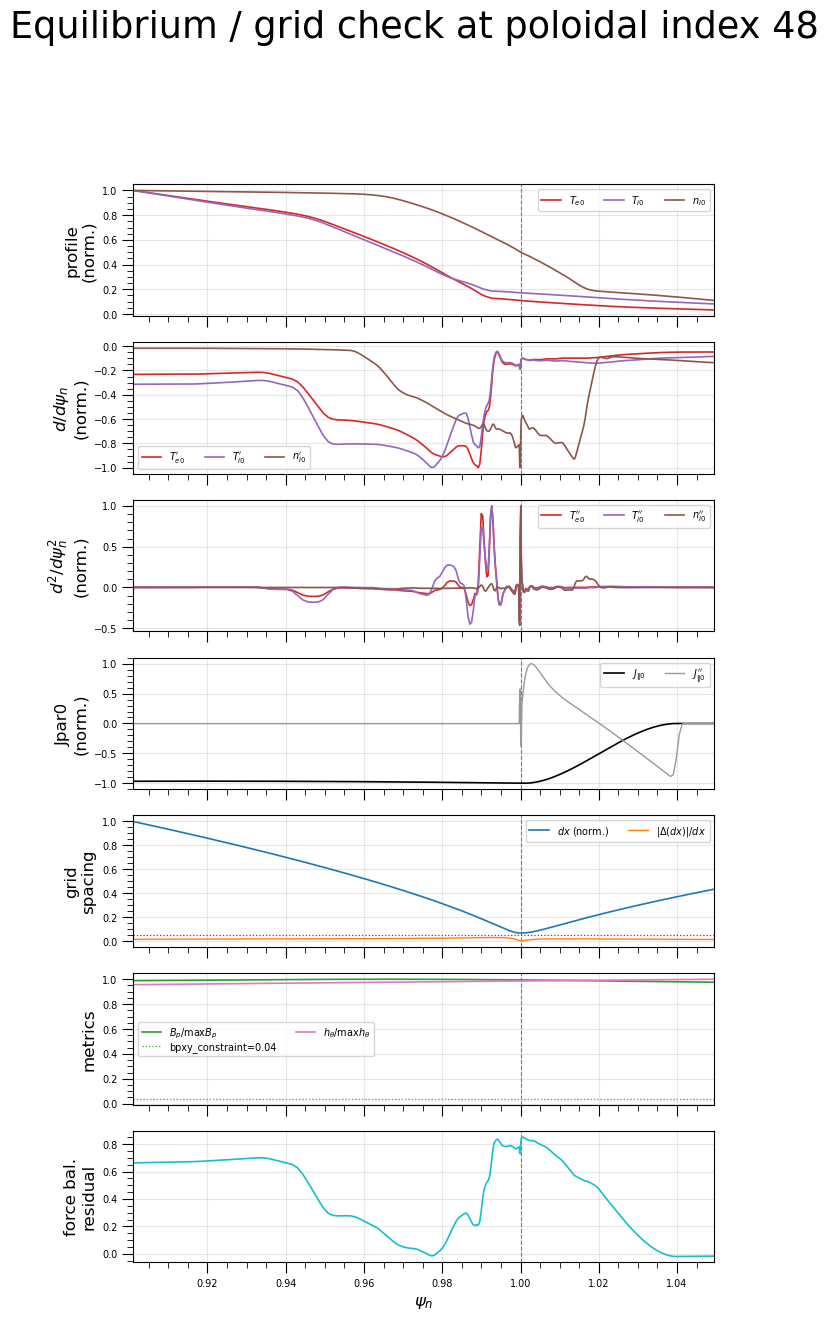

3/6  2*dx odd-even (checkerboard) content
  saved ./crash_diagnostics/sawtooth_j48.png


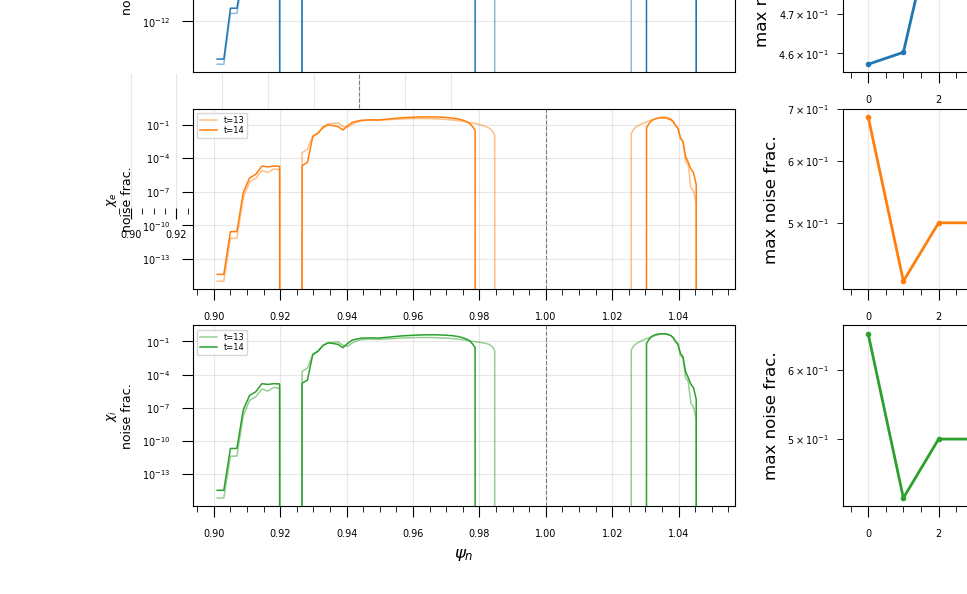

4/6  growth tracking and first non-finite cell
field             first bad t  bad cells   psi_n of peak @ last t
--------------------------------------------------------------------
Da_t                        -          0    0.9896 (ix=82, iy=62)
Xe_t                        -          0    0.9870 (ix=76, iy=63)
Xi_t                        -          0   0.9971 (ix=110, iy=62)
ddr_nitot_txy               -          0      0.9010 (ix=0, iy=0)
ddr_Tetot_txy               -          0      0.9010 (ix=0, iy=0)
ddr_Titot_txy               -          0      0.9010 (ix=0, iy=0)
  saved ./crash_diagnostics/growth.png
5/6  poloidal localisation and velocity decomposition
  saved ./crash_diagnostics/poloidal_localization_t14.png


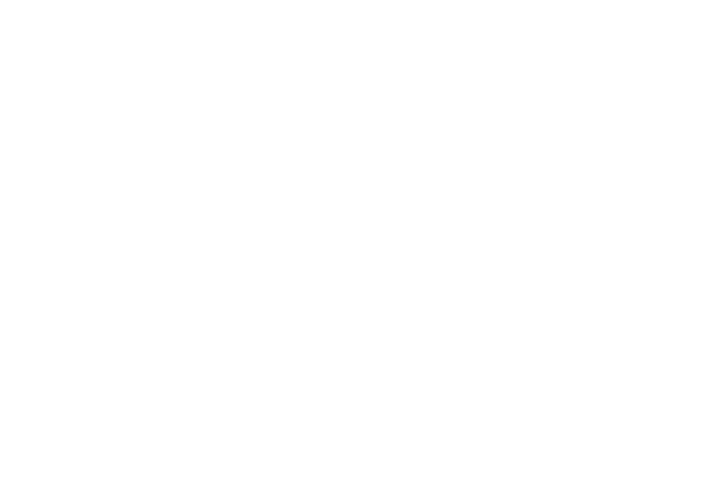

missing Vr_t -- cannot run velocity consistency check
6/6  frozen-field check (does anything actually evolve?)
array                   max|f(t)-f(0)|         rel   verdict
----------------------------------------------------------------------
Da_t                        1.9163e+04    1.24e+16   evolving
Xe_t                        1.5773e+01    5.49e+12   evolving
Xi_t                        1.4876e+02    2.53e+13   evolving
ddr_Tetot_txy               5.1388e+04    1.00e+00   evolving
ddr_Titot_txy               5.7382e+04    1.00e+00   evolving
ddr_nitot_txy               4.1434e+01    1.00e+00   evolving

All figures written to: /global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_jpar_repair_only/0_iteration/crash_diagnostics


In [2]:
import sibil_debug_diagnostics as dbg
display(dbg.make_debug_widget(convergent_transport_coeffs, psin_mid,
                              jomp=jomp, grid=grid, data_dir=data_dir))
dbg.full_report(convergent_transport_coeffs, psin_mid, grid_fname,
                jomp=jomp, savedir="./crash_diagnostics")